# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the Planet UAS multi label dataset.

In [ ]:
from aitlas.datasets import PlanetUASMultiLabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ConvertToRGBResizeCenterCropToTensor, ResizeCenterCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/PlanetUAS/images",
    "csv_file": "/home/dragik/data/PlanetUAS/multilabels.txt",
}
dataset = PlanetUASMultiLabelDataset(dataset_config)

## Show images from the dataset

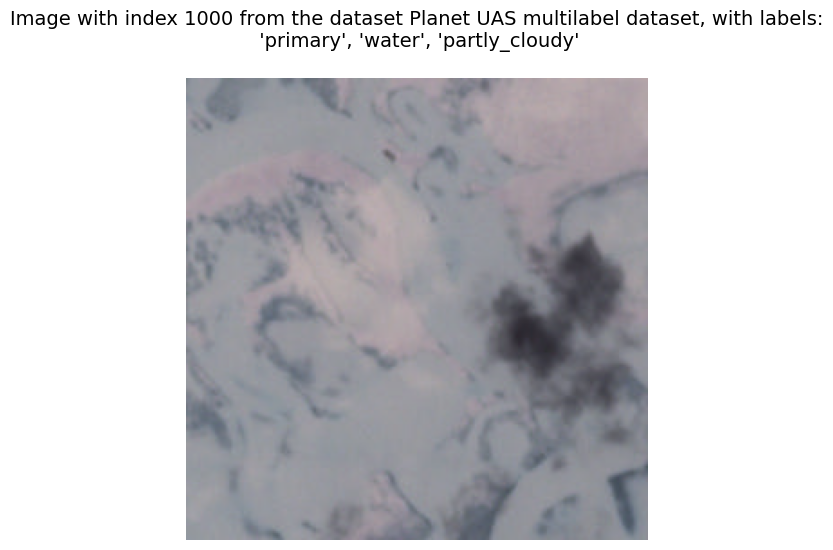

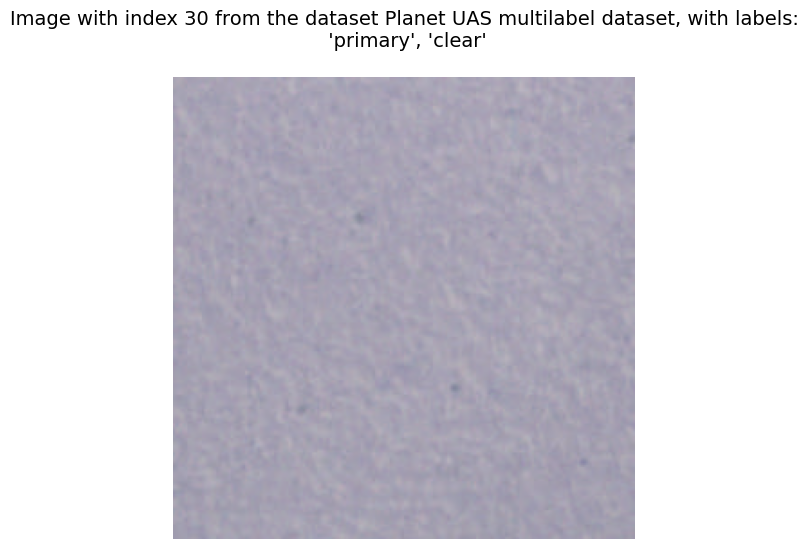

In [5]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)

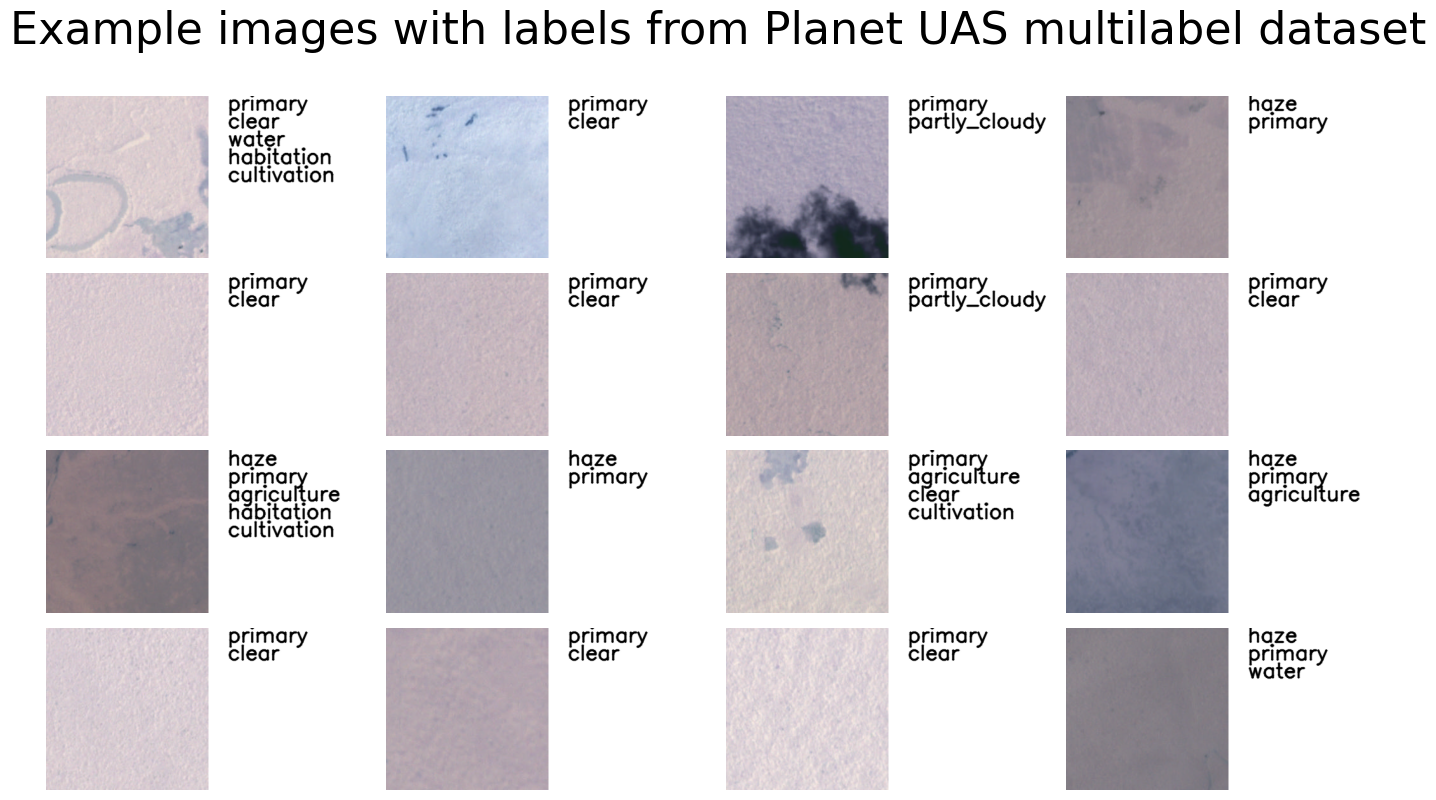

In [7]:
fig3 = dataset.show_batch(16)

## Inspect the data

In [8]:
dataset.show_samples()

,image,haze,primary,agriculture,clear,water,habitation,road,cultivation,slash_burn,cloudy,partly_cloudy,conventional_mine,bare_ground,artisinal_mine,blooming,selective_logging,blow_down
0,train_0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,train_1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
2,train_2,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,train_3,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
4,train_4,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0
5,train_5,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
6,train_6,0,1,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0
7,train_7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,train_8,0,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0
9,train_9,0,1,1,1,0,0,1,1,0,0,0,0,0,0,0,0,0


In [9]:
dataset.data_distribution_table()

,Label,Count
1,haze,2697
2,primary,37513
3,agriculture,12315
4,clear,28431
5,water,7411
6,habitation,3660
7,road,8071
8,cultivation,4477
9,slash_burn,209
10,cloudy,2089


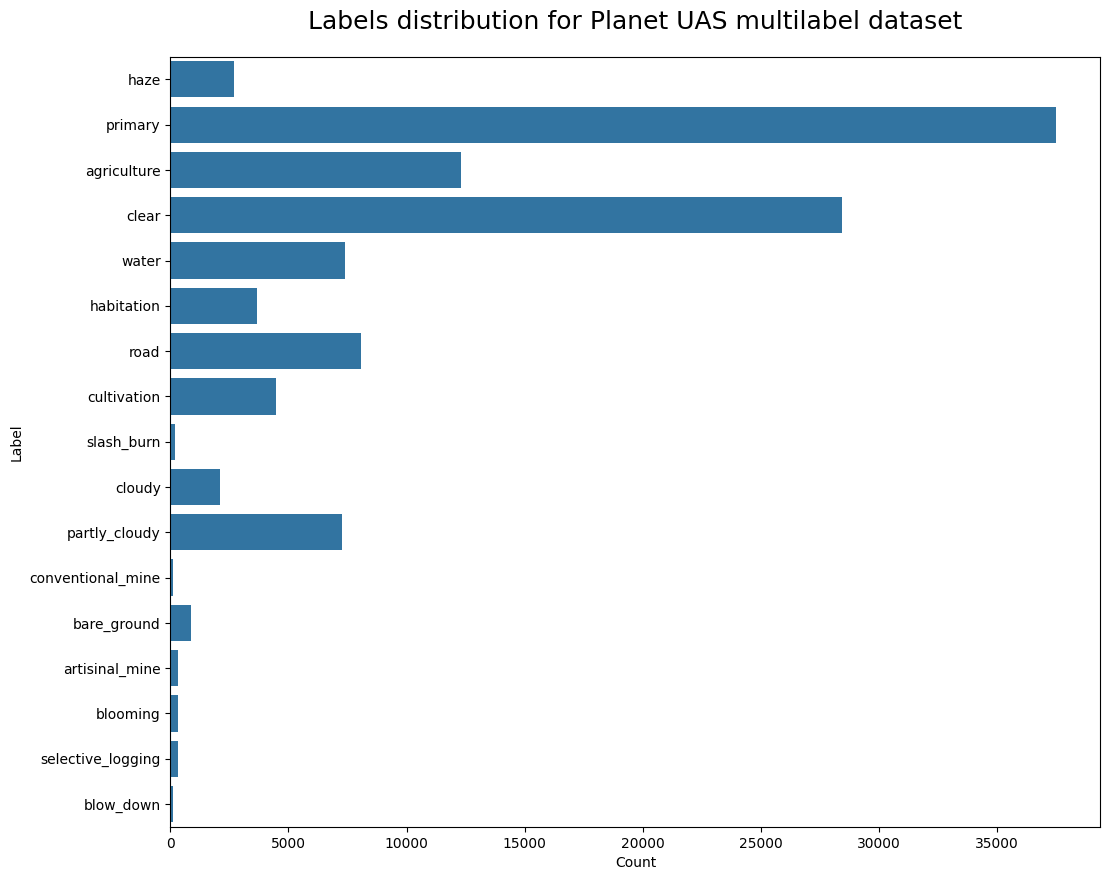

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [18]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/PlanetUAS/images",
    "csv_file": "/home/dragik/data/PlanetUAS/train.csv",
}

train_dataset = PlanetUASMultiLabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/PlanetUAS/images",
    "csv_file": "/home/dragik/data/PlanetUAS/val.csv",
}

test_dataset = PlanetUASMultiLabelDataset(test_dataset_config)
test_dataset.transform = ResizeCenterCropFlipHVToTensor()
len(train_dataset), len(test_dataset)

(24253, 8117)

## Setup and create the model for training

In [19]:
epochs = 10
model_directory = "/home/dragik/data/experiments/PlanetUAS"
model_config = {
    "num_classes": 17,
    "learning_rate": 0.0001,
    "pretrained": True,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [20]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 09:45:32,350 INFO Starting training.
training: 100%|██████████| 1516/1516 [01:10<00:00, 21.57it/s]
2026-08-24 09:46:42,706 INFO epoch: 1, time: 70, loss:  0.16330
testing on train set: 100%|██████████| 1516/1516 [00:30<00:00, 49.30it/s]
2026-08-24 09:47:14,409 INFO Accuracy:0.9597284508162726, Accuracy per Class:[0.95101637 0.95781965 0.88887973 0.93984249 0.91324785 0.94709933
 0.92561745 0.90586732 0.994846   0.97542572 0.96103575 0.99773224
 0.97950769 0.99616542 0.99212469 0.99183606 0.99731992], Precision Micro:0.9110146500271297, Precision Macro:0.5759402959928565, Precision Weighted:0.8972052994652715, Precision per Class:[0.88129496 0.98893946 0.83480742 0.93297483 0.83385849 0.7707346
 0.88116818 0.58392226 0.         0.70340557 0.95831063 0.
 0.58823529 0.83333333 0.         0.         0.        ], Recall Micro:0.8439730572031768, Recall Macro:0.4707242639267914, Recall Weighted:0.8439730572031768, Recall per Class:[0.30397022 0.96534412 0.79198809 0.98536214 0.656

0.08118431307823214

## Predictions

2026-08-24 10:16:06,847 INFO Loading checkpoint /home/dragik/data/experiments/PlanetUAS/checkpoint.pth.tar
2026-08-24 10:16:07,545 INFO Loaded checkpoint /home/dragik/data/experiments/PlanetUAS/checkpoint.pth.tar at epoch 11


8109


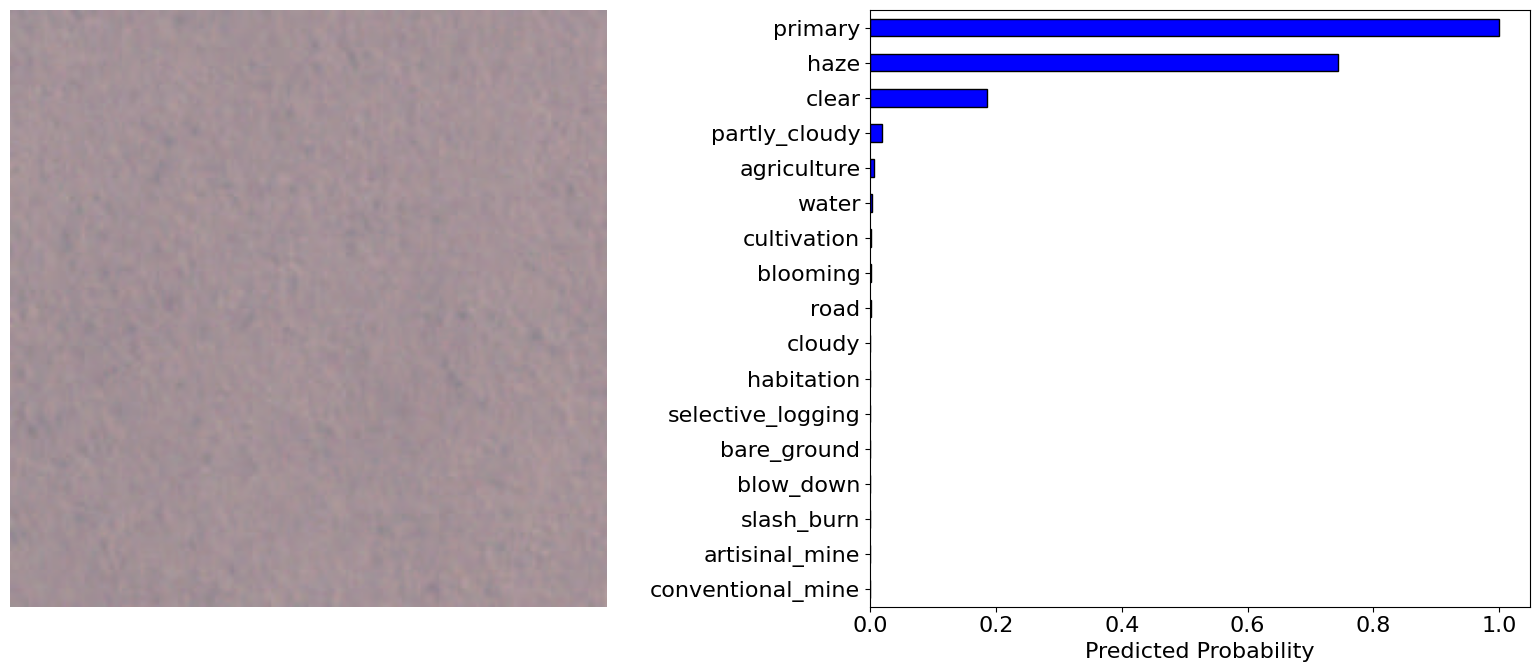

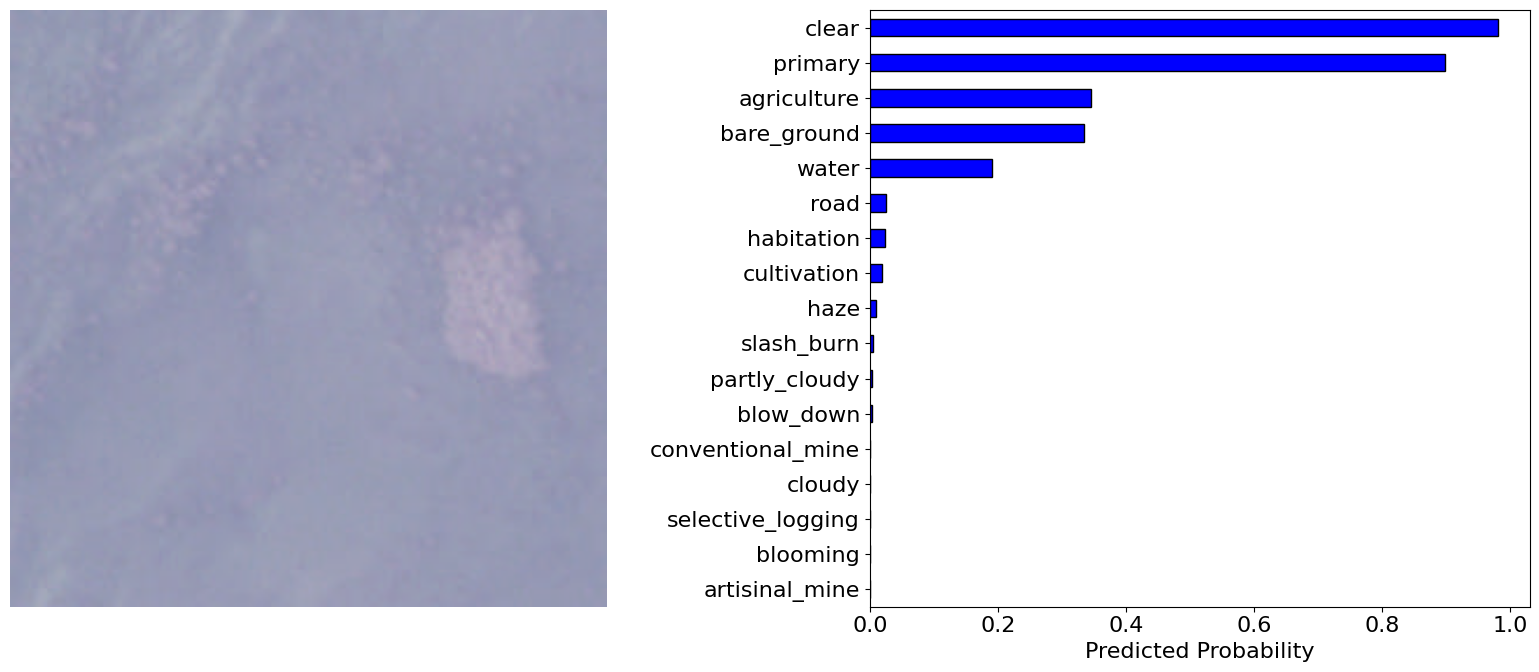

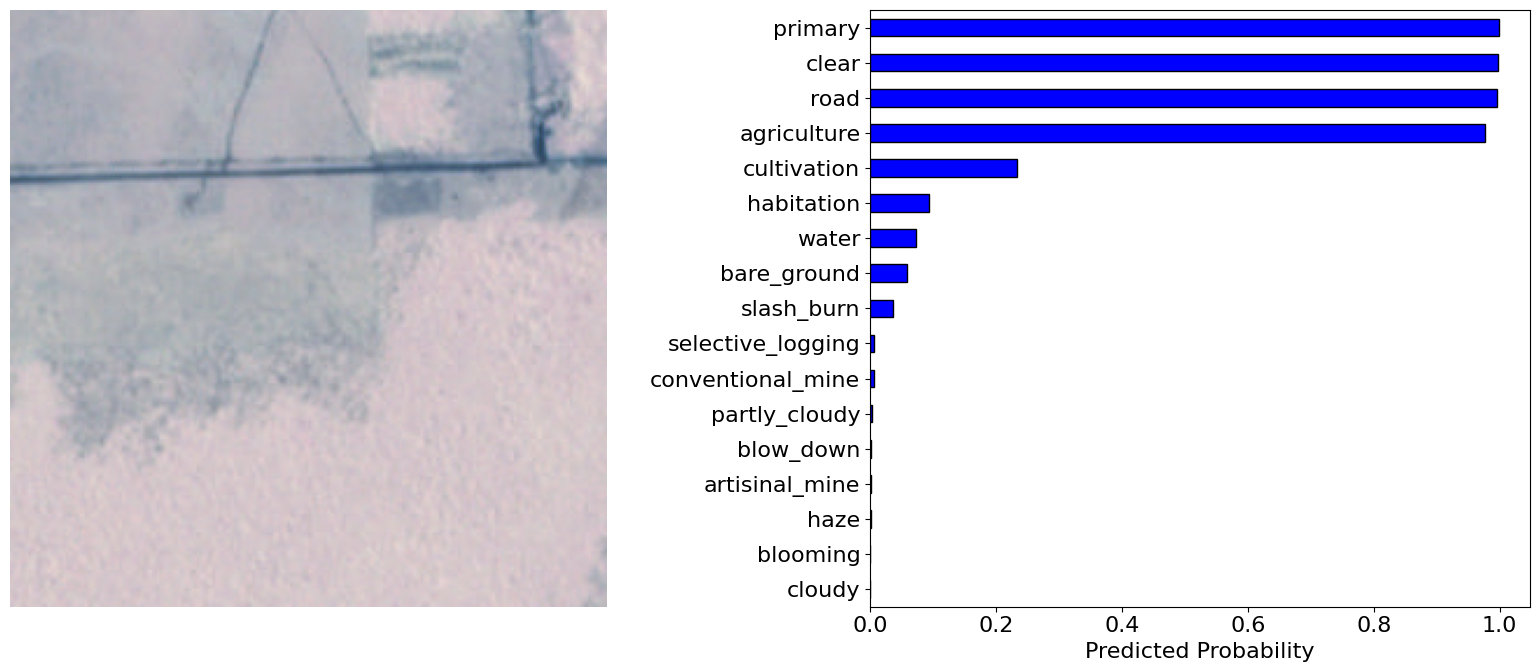

In [21]:
model_path = "/home/dragik/data/experiments/PlanetUAS/checkpoint.pth.tar"
labels = [
    "haze",
    "primary",
    "agriculture",
    "clear",
    "water",
    "habitation",
    "road",
    "cultivation",
    "slash_burn",
    "cloudy",
    "partly_cloudy",
    "conventional_mine",
    "bare_ground",
    "artisinal_mine",
    "blooming",
    "selective_logging",
    "blow_down",
]
transform = ConvertToRGBResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/PlanetUAS/images",
    "csv_file": "/home/dragik/data/PlanetUAS/test.csv",
}

test_dataset = PlanetUASMultiLabelDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)